# ¿Qué periodos concentran más variación?
Periodograma con ventana Hann y transformada Morlet (frecuencia adimensional 6). El blanco señala bordes excluidos. El máximo se busca entre 1,5 y 16 años. Son estimaciones descriptivas de potencia individual.
Ejecuta las celdas en orden. Las tablas CSV y figuras se guardan en la carpeta de trabajo.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/gretadive/correlacion_actividad_solar_elnino/751cd7c187616d8b7ed7b175280dc80a4e999a29/data/processed/dataset_integrado_precipitacion.csv"
archivo = Path("datos.csv")
df = pd.read_csv(archivo if archivo.exists() else url, parse_dates=["fecha"])
df = df.set_index("fecha").sort_index().asfreq("MS")
variables = ["ICEN", "ONI", "precipitacion_mm"]
assert len(df) == 917 and df[variables + ["SSN"]].notna().all().all()
desfases = [0, 3, 6, 12, 24]


serie  periodo_dominante_anios
  SSN                    10.92
 ICEN                     3.64
  ONI                     3.64


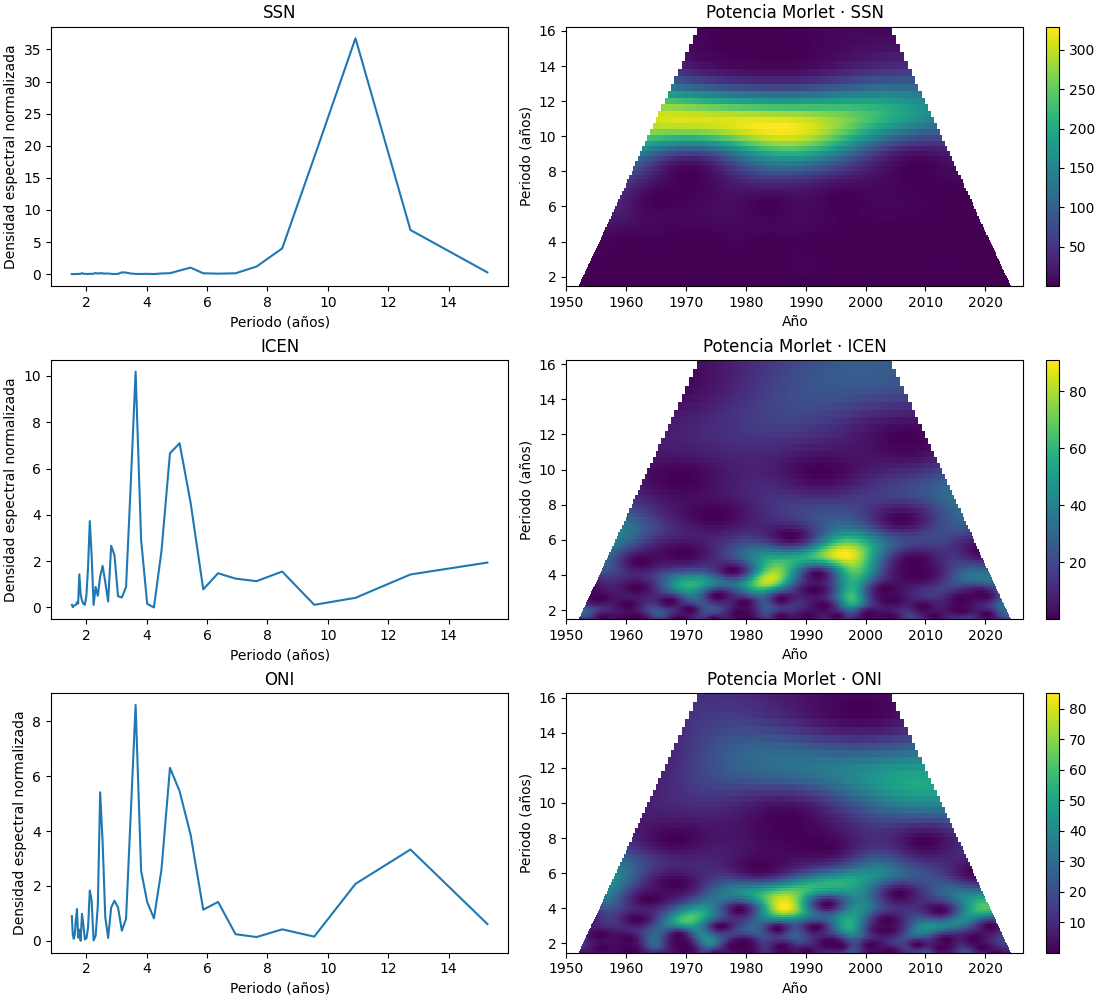

In [ ]:
from scipy.signal import periodogram, detrend, fftconvolve
periodos = np.geomspace(1.5,16,75)
filas = []
fig, axes = plt.subplots(3,2,figsize=(11,10),layout="constrained")
for i,v in enumerate(["SSN","ICEN","ONI"]):
    x = detrend(df[v].to_numpy())
    x /= x.std()
    f,p = periodogram(x,fs=12,window="hann")
    banda = (f >= 1/16) & (f <= 1/1.5)
    dominante = 1/f[banda][np.argmax(p[banda])]
    filas.append([v,dominante])
    ax, mapa = axes[i]
    ax.plot(1/f[banda],p[banda])
    ax.set(title=v, xlabel="Periodo (años)",ylabel="Densidad espectral normalizada")
    potencia = []
    for periodo in periodos:
        escala = periodo*12*(6+np.sqrt(38))/(4*np.pi)
        t = np.arange(-np.ceil(5*escala),np.ceil(5*escala)+1)/escala
        onda = np.exp(6j*t-t*t/2)/np.sqrt(escala)
        valores = abs(fftconvolve(x,np.conj(onda[::-1]),mode="same"))**2
        margen = int(np.ceil(np.sqrt(2)*escala))
        valores[:margen] = np.nan
        valores[-margen:] = np.nan
        potencia.append(valores)
    imagen = mapa.pcolormesh(df.index,periodos,potencia,shading="auto",cmap="viridis")
    mapa.set(title="Potencia Morlet · "+v, ylabel="Periodo (años)", xlabel="Año")
    fig.colorbar(imagen, ax=mapa)
fig.savefig("13_periodicidad.png",dpi=160)
plt.show()
picos = pd.DataFrame(filas,columns=["serie","periodo_dominante_anios"])
picos.to_csv("13_periodos.csv",index=False)
print(picos.round(2).to_string(index=False))
